In [93]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [94]:
import  pandas  as pd
pd.set_option('display.max_columns', None)
url = "/content/drive/MyDrive/Colab Notebooks/bigdata/"
df = pd.read_csv(url+"hotel_bookings.csv")
df.sample(5)

,hotel,lead_time,arrival_month,adults,children,babies,country,market_segment,deposit_type,customer_type,adr,previous_cancellations,special_requests,is_canceled
386,Resort Hotel,9,Sep,2,0.0,0,FRA,Offline,Refundable,Contract,112.0,3,4,0
419,City Hotel,201,May,2,0.0,0,JPN,Online,Refundable,Transient,345.0,0,0,0
327,Resort Hotel,116,Apr,1,1.0,0,JPN,Offline,Non Refund,Transient,238.0,5,2,0
66,City Hotel,172,Sep,2,1.0,0,FRA,Online,Refundable,Group,232.0,3,1,1
443,City Hotel,235,Jul,3,0.0,0,USA,Online,Non Refund,Contract,212.0,0,3,0


In [95]:
df.describe()

,lead_time,adults,children,babies,adr,previous_cancellations,special_requests,is_canceled
count,457.000000,457.000000,449.000000,457.000000,452.000000,457.000000,457.000000,457.000000
mean,181.516411,2.317287,0.389755,0.045952,229.280973,2.595186,2.048140,0.660832
std,131.235593,1.364488,0.669476,0.209610,270.274359,1.679409,1.385182,0.473946
min,0.000000,1.000000,0.000000,0.000000,-50.000000,0.000000,0.000000,0.000000
25%,95.000000,2.000000,0.000000,0.000000,143.000000,1.000000,1.000000,0.000000
50%,176.000000,2.000000,0.000000,0.000000,225.000000,3.000000,2.000000,1.000000
75%,258.000000,3.000000,1.000000,0.000000,281.250000,4.000000,3.000000,1.000000
max,1500.000000,20.000000,2.000000,1.000000,5000.000000,5.000000,4.000000,1.000000


In [96]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 457 entries, 0 to 456
Data columns (total 14 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   hotel                   457 non-null    object 
 1   lead_time               457 non-null    int64  
 2   arrival_month           457 non-null    object 
 3   adults                  457 non-null    int64  
 4   children                449 non-null    float64
 5   babies                  457 non-null    int64  
 6   country                 450 non-null    object 
 7   market_segment          457 non-null    object 
 8   deposit_type            453 non-null    object 
 9   customer_type           457 non-null    object 
 10  adr                     452 non-null    float64
 11  previous_cancellations  457 non-null    int64  
 12  special_requests        457 non-null    int64  
 13  is_canceled             457 non-null    int64  
dtypes: float64(2), int64(6), object(6)
memory 

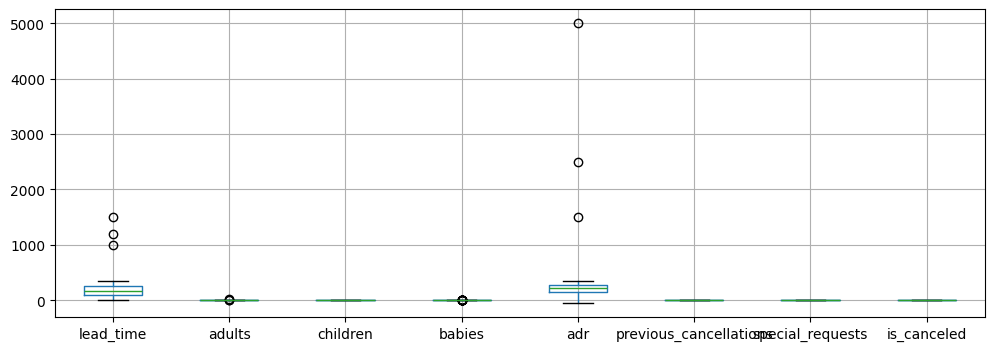

In [97]:
import matplotlib.pyplot as plt
plt.figure(figsize=(12,4))
df2 = df.drop(columns=['lead_time', 'adr'])
df.boxplot()
#df2.boxplot()
plt.show()

In [98]:
df3 = df[df["adults"] == 20] # 개별 고객이 성인 20명은 이상치로 판단
df3

,hotel,lead_time,arrival_month,adults,children,babies,country,market_segment,deposit_type,customer_type,adr,previous_cancellations,special_requests,is_canceled
83,City Hotel,149,Jan,20,1.0,0,KOR,Corporate,Non Refund,Transient,202.0,3,2,0


In [99]:
# 결측치 제거
print(df.shape)
df = df.dropna(subset=['children'])
df = df.dropna(subset=['country'])
df = df.dropna(subset=['deposit_type'])
df = df.dropna(subset=['adr'])
print(df.shape)
#df.info()

(457, 14)
(433, 14)


In [100]:
# 이상치 제거 : adults == 20 케이스는 후보로 둠
# lead_time: 0~350, adr : 50~350 벗어나는 값은 삭제
df = df[(df["lead_time"] >= 0) & (df["lead_time"] <= 350) & (df["adr"] >= 50) & (df["adr"] <= 350)]

In [101]:
df.describe()

,lead_time,adults,children,babies,adr,previous_cancellations,special_requests,is_canceled
count,426.000000,426.000000,426.000000,426.000000,426.000000,426.000000,426.000000,426.000000
mean,176.152582,2.281690,0.399061,0.049296,211.612676,2.610329,2.039906,0.673709
std,97.947033,1.252008,0.675904,0.216739,84.100851,1.658713,1.375689,0.469406
min,0.000000,1.000000,0.000000,0.000000,50.000000,0.000000,0.000000,0.000000
25%,95.000000,2.000000,0.000000,0.000000,143.250000,1.000000,1.000000,0.000000
50%,177.000000,2.000000,0.000000,0.000000,224.500000,3.000000,2.000000,1.000000
75%,256.750000,3.000000,1.000000,0.000000,279.750000,4.000000,3.000000,1.000000
max,349.000000,20.000000,2.000000,1.000000,348.000000,5.000000,4.000000,1.000000


In [102]:
df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 426 entries, 0 to 456
Data columns (total 14 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   hotel                   426 non-null    object 
 1   lead_time               426 non-null    int64  
 2   arrival_month           426 non-null    object 
 3   adults                  426 non-null    int64  
 4   children                426 non-null    float64
 5   babies                  426 non-null    int64  
 6   country                 426 non-null    object 
 7   market_segment          426 non-null    object 
 8   deposit_type            426 non-null    object 
 9   customer_type           426 non-null    object 
 10  adr                     426 non-null    float64
 11  previous_cancellations  426 non-null    int64  
 12  special_requests        426 non-null    int64  
 13  is_canceled             426 non-null    int64  
dtypes: float64(2), int64(6), object(6)
memory usage

In [103]:
df["country"].unique()

array(['KOR', 'GBR', 'FRA', 'JPN', 'USA', 'CHN'], dtype=object)

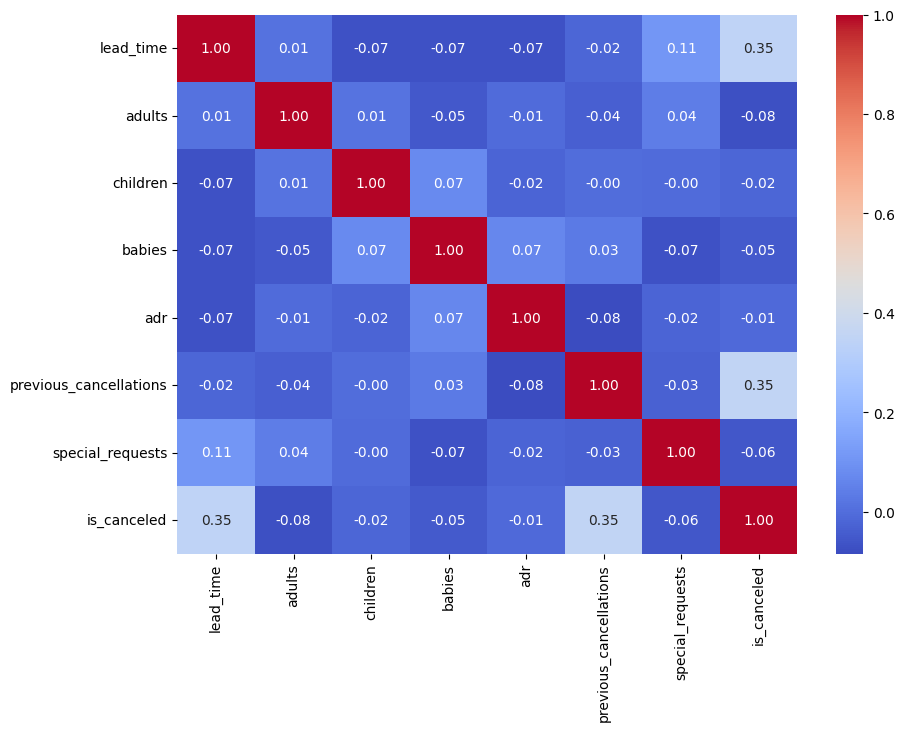

In [104]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(10, 7))
sns.heatmap(
    df.corr(numeric_only=True),
    annot=True,
    cmap='coolwarm',
    fmt='.2f'
)
plt.show()

In [105]:
X = df.drop(columns=['is_canceled'])
y = df['is_canceled']

In [106]:
# 데이터 분리
from sklearn.model_selection import train_test_split
train_input, test_input, train_target, test_target = train_test_split(X, y, random_state = 42, test_size = 0.3, stratify = y)
print(train_input.shape, test_input.shape, train_target.shape, test_target.shape)

(298, 13) (128, 13) (298,) (128,)


In [107]:
from sklearn.preprocessing import LabelEncoder

train_input = train_input.copy()
test_input = test_input.copy()

columns = [
    "hotel",
    "arrival_month",
    "country",
    "market_segment",
    "deposit_type",
    "customer_type",
]

for col in columns:
  le = LabelEncoder()
  # train_input으로 학습 및 변환
  train_input[col] = le.fit_transform(train_input[col])
  # test_input에 동일 인코더 적용 (학습되지 않은 값 처리를 위해 예외 처리 추가 가능)
  test_input[col] = test_input[col].map(
      lambda s: le.transform([s])[0] if s in le.classes_ else -1
  )

#print(train_input.head())
#print(test_input.head())

In [110]:
# 데이터 표준화
from sklearn.preprocessing import StandardScaler
scaler = StandardScaler()

# 테스트 데이터로 훈련 데이터 특성이 누수되는 것을 막기 위해 훈련 데이터에만 fit()
train_scaled = scaler.fit_transform(train_input)
test_scaled = scaler.transform(test_input)

In [111]:
# LogisticRegression
from sklearn.linear_model import LogisticRegression
lr = LogisticRegression(max_iter = 1000)
lr.fit(train_scaled, train_target)
print(lr.score(train_scaled, train_target))
print(lr.score(test_scaled, test_target))

0.8422818791946308
0.8125


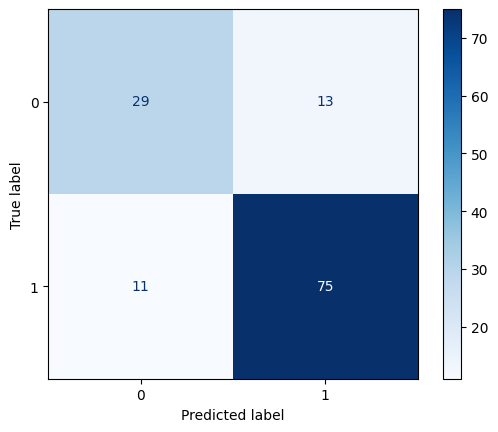

정확도 : 0.8125
정밀도 : 0.8522727272727273
재현율 : 0.872093023255814
특이도 : 0.6904761904761905


In [113]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
ConfusionMatrixDisplay.from_estimator(
    lr,
    test_scaled, test_target,
    cmap = 'Blues'
)
plt.show()

tp = 75; fp = 13; fn = 11; tn = 29
print("정확도 :", (tp+tn)/(tp+fp+fn+tn))
print("정밀도 :", tp/(tp+fp))
print("재현율 :", tp/(tp+fn))
print("특이도 :", tn/(tn+fp))

In [114]:
# KNeighborsClassifier
from sklearn.neighbors import KNeighborsClassifier
kn = KNeighborsClassifier(n_neighbors = 5)
kn.fit(train_scaled, train_target)
print(kn.score(train_scaled, train_target))
print(kn.score(test_scaled, test_target))

0.8120805369127517
0.78125


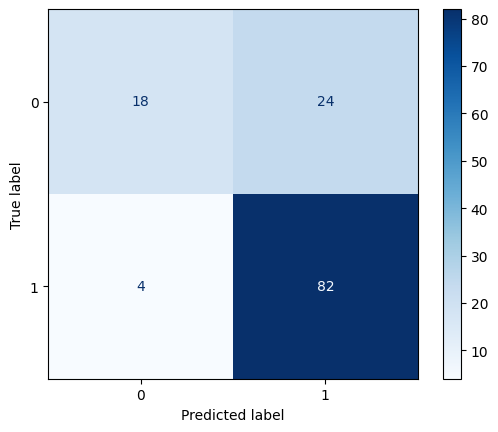

정확도 : 0.78125
정밀도 : 0.7735849056603774
재현율 : 0.9534883720930233
특이도 : 0.42857142857142855


In [117]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
ConfusionMatrixDisplay.from_estimator(
    kn,
    test_scaled, test_target,
    cmap = 'Blues'
)
plt.show()

tp = 82; fp = 24; fn = 4; tn = 18
print("정확도 :", (tp+tn)/(tp+fp+fn+tn))
print("정밀도 :", tp/(tp+fp))
print("재현율 :", tp/(tp+fn))
print("특이도 :", tn/(tn+fp))

In [118]:
# DecisionTreeClassifier
from sklearn.tree import DecisionTreeClassifier
dt = DecisionTreeClassifier(
    #max_depth = 6,
    random_state = 42
)
dt.fit(train_scaled, train_target)
print(dt.score(train_scaled, train_target))
print(dt.score(test_scaled, test_target))

1.0
0.984375


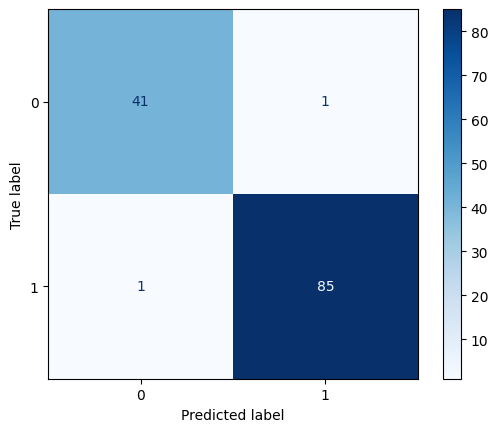

정확도 : 0.984375
정밀도 : 0.9883720930232558
재현율 : 0.9883720930232558
특이도 : 0.9761904761904762


In [120]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
ConfusionMatrixDisplay.from_estimator(
    dt,
    test_scaled, test_target,
    cmap = 'Blues'
)
plt.show()

tp = 85; fp = 1; fn = 1; tn = 41
print("정확도 :", (tp+tn)/(tp+fp+fn+tn))
print("정밀도 :", tp/(tp+fp))
print("재현율 :", tp/(tp+fn))
print("특이도 :", tn/(tn+fp))

In [121]:
# RandomForestClassifier
from sklearn.ensemble import RandomForestClassifier
rf = RandomForestClassifier(n_estimators = 100, min_samples_split = 2, random_state = 42)
rf.fit(train_scaled, train_target)
print(rf.score(train_scaled, train_target))
print(rf.score(test_scaled, test_target))

1.0
0.953125


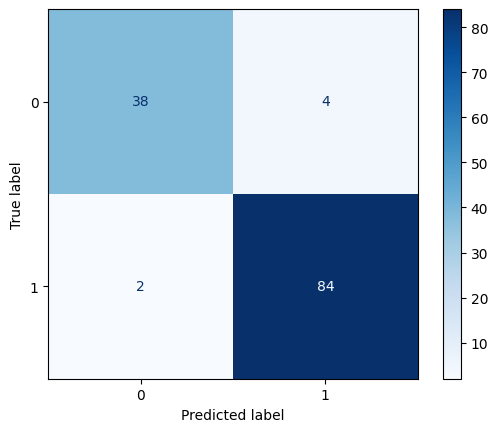

정확도 : 0.953125
정밀도 : 0.9545454545454546
재현율 : 0.9767441860465116
특이도 : 0.9047619047619048


In [123]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
ConfusionMatrixDisplay.from_estimator(
    rf,
    test_scaled, test_target,
    cmap = 'Blues'
)
plt.show()

tp = 84; fp = 4; fn = 2; tn = 38
print("정확도 :", (tp+tn)/(tp+fp+fn+tn))
print("정밀도 :", tp/(tp+fp))
print("재현율 :", tp/(tp+fn))
print("특이도 :", tn/(tn+fp))